# ADD runtime pilot: assignment, GDF versus Best Cost

Eight paired comparisons (16 solver runs): n = 12 and 16, linear and entropic objectives,
two optimizer seeds per setting. Two seeds share a fixed objective; they are not two independent problem instances.
The 10-iteration checkpoint belongs to the same uninterrupted 20-iteration run.

**Protocol:** 1,000 initial feasible draws; 10,000 TT samples per iteration;
50 retained elites; fill the candidate pool to 20,000 with uniform random permutations.
Select 1,000 points, retain elites as in the production solver; 20 iterations,
one training sweep, learning rate 0.05, charge degeneracy one, GDF filter weight 0.4.
No EELS, barrier, worst retention, or objective cache. The TT is rebuilt every iteration.
Sampling backend: `table`; factorization: `fast`. One Julia default thread, one GC thread,
one BLAS thread, and affinity to one logical CPU on a distinct physical core per process.

Linear coefficients are the existing `data/random_vectors/c_{n}_1_r=50.jld2`.
Entropic coefficients use a fixed independent seed `20261020 + 100*n`:
c_j ~ U[-1,1], 32 independent Gaussian scenario vectors, tau = 0.5,
and s = sqrt(2*n), the square root of the number of assignment equality rows.
The cost is c'x/s + tau*log(mean(exp(W*x/(tau*s)))), evaluated stably.
This extends the article's entropic formula to assignment; it is not the earlier linear-only tuning dataset.

Each pair uses identical initial draws and model/source RNG seeds. The source owns its RNG.
Later requested source batch sizes may differ as TT sample uniqueness changes.
Replicate 1 runs Best Cost then GDF; replicate 2 reverses the order.
The accepted measurements run sequentially, with CPU affinity. A preliminary four-worker attempt
exhausted the machine's 8 GiB RAM; those interrupted measurements are archived separately
under `data/add_runtime_pilot_20261020_memory_pressure_discarded` and excluded.
Compilation and small-case warm-up are excluded; measured time includes initialization, all 20 iterations,
objective calls and tiny checkpoint-writing overhead. Both arms pay the same instrumentation.
The original solver is unchanged: its current source is cloned in memory with phase timers.
Toy linear/entropic cases verify exact incumbent and learning-curve agreement with production.
The production solver maintains charge history in both strategies, but evaluates graph distances only
for GDF. This comparison preserves that behavior rather than optimizing Best Cost specially.


## Hardware and interpretation

```json
{
  "cpu": "Intel(R) Core(TM) i5-10210U CPU @ 1.60GHz",
  "physical_core_masks": [
    1,
    4,
    16,
    64
  ],
  "used_masks": [
    1,
    4,
    16,
    64
  ],
  "logical_cpus": 8,
  "concurrent_workers": 1,
  "one_logical_cpu_per_worker": true,
  "memory_at_start": {
    "length": 64,
    "load_pct": 60,
    "total": 8415133696,
    "available": 3332870144,
    "page_total": 27742486528,
    "page_available": 13018820608,
    "virtual_total": 140737488224256,
    "virtual_available": 140733075849216,
    "extended": 0
  },
  "julia": "C:\\Users\\serge\\.julia\\juliaup\\julia-1.12.5+0.x64.w64.mingw32\\bin\\julia.exe",
  "created_at": "2026-10-20T12:53:23+0300",
  "protocol": "2 sizes x 2 objectives x 2 optimizer seeds x 2 strategies; no objective cache"
}
```

This is a local timing pilot, not a statistical significance study. The final measurements use one worker; background applications, thermal and frequency limits remain uncontrolled. Ratios are paired but not perfectly isolated kernel measurements. The full trajectory is measured, so any change in training/topology costs caused by selection is included. Graph distance is timed separately; it performs no objective evaluations. It is part of selection time and must not be added to it a second time. RSS/private memory are sampled every second during the timed region, include runtime overhead, and can miss shorter peaks. Cumulative allocated bytes are not peak live memory. No claim about multi-thread graph-distance scaling is tested by this one-thread experiment.

## Status

Completed solver arms: **16/16**. Rows below appear only when both arms have reached the checkpoint.

Additional protocol checks:

- best_cost, linear n=12: final cost reproduces the saved article-tuning result.
- gdf, linear n=12: final cost reproduces the saved article-tuning result.
- best_cost, linear n=16: final cost reproduces the saved article-tuning result.
- gdf, linear n=16: final cost reproduces the saved article-tuning result.

In [1]:
from pathlib import Path
import sys
root = Path.cwd()
if not (root / "Project.toml").exists():
    root = root.parent
sys.path.insert(0, str(root / "scripts"))
from add_runtime_report import *
from IPython.display import HTML, Image, display
arms = load()
cp = checkpoints(arms)
paired = pairs(cp, arms)
groups = aggregate(paired)
display(HTML(html_table(groups, GROUP_COLUMNS)))

Iterations,n,Objective,Pairs,Best Cost (s),GDF (s),GDF / Best time,GDF improvement (%),Graph / GDF time (%),Best peak RSS (MiB),GDF peak RSS (MiB)
10,12,linear,2,10.1,25.9,2.56,1.7,32.2,1458.5,1423.6
10,12,entropic,2,12.2,28.2,2.31,1.7,31.0,1447.3,1408.5
10,16,linear,2,29.5,71.4,2.42,7.9,24.3,1587.5,1730.1
10,16,entropic,2,32.6,80.9,2.48,5.8,24.4,1726.9,1773.3
20,12,linear,2,16.2,47.0,2.90,1.9,38.1,1475.2,1423.6
20,12,entropic,2,19.4,53.6,2.77,1.0,33.5,1450.1,1408.5
20,16,linear,2,44.6,131.6,2.95,9.0,27.9,1587.5,1733.1
20,16,entropic,2,49.7,148.0,2.98,13.1,27.2,1726.9,1837.2


Arithmetic means over the two seeds. Time ratio is the mean paired GDF/Best Cost ratio; values above one mean slower GDF. Positive relative improvement means lower GDF cost. Individual seeds are retained below; two repeats do not support reliable confidence intervals.

## Elapsed time versus completed iteration

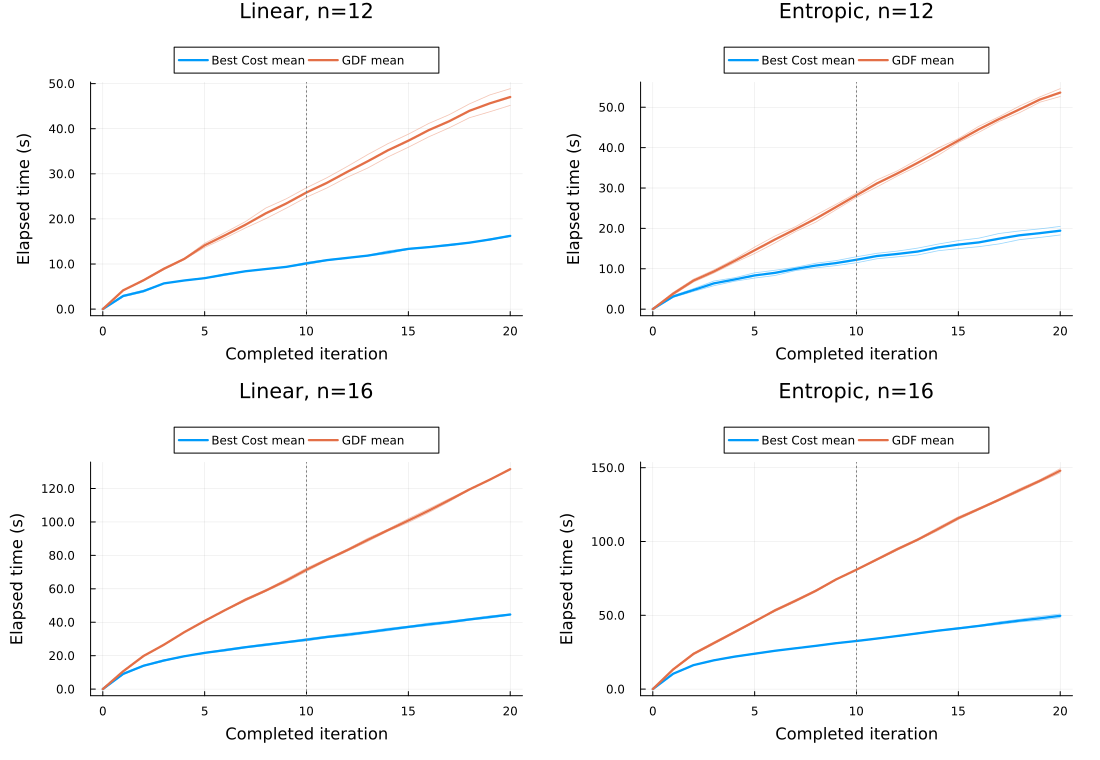

In [2]:
display(Image(filename=str(root / "examples/add_runtime_pilot/time_by_iteration.png")))

## Improvement over the common initial incumbent

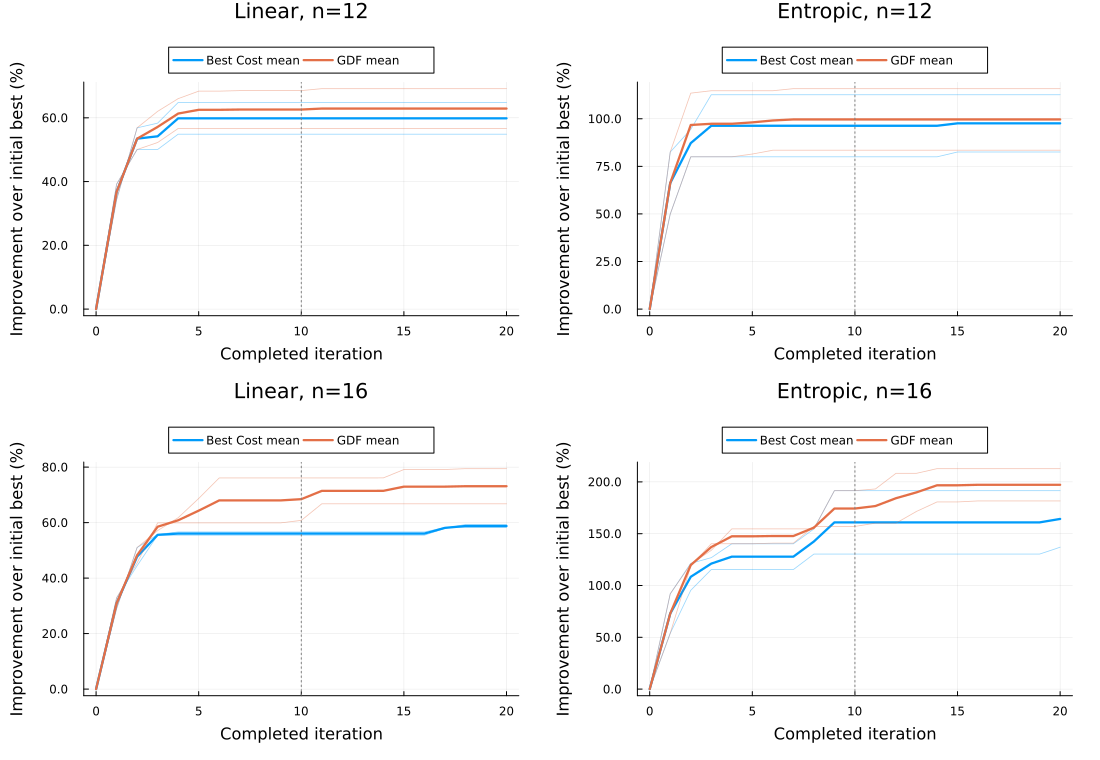

In [3]:
display(Image(filename=str(root / "examples/add_runtime_pilot/gain_by_iteration.png")))

## Improvement versus elapsed optimization time

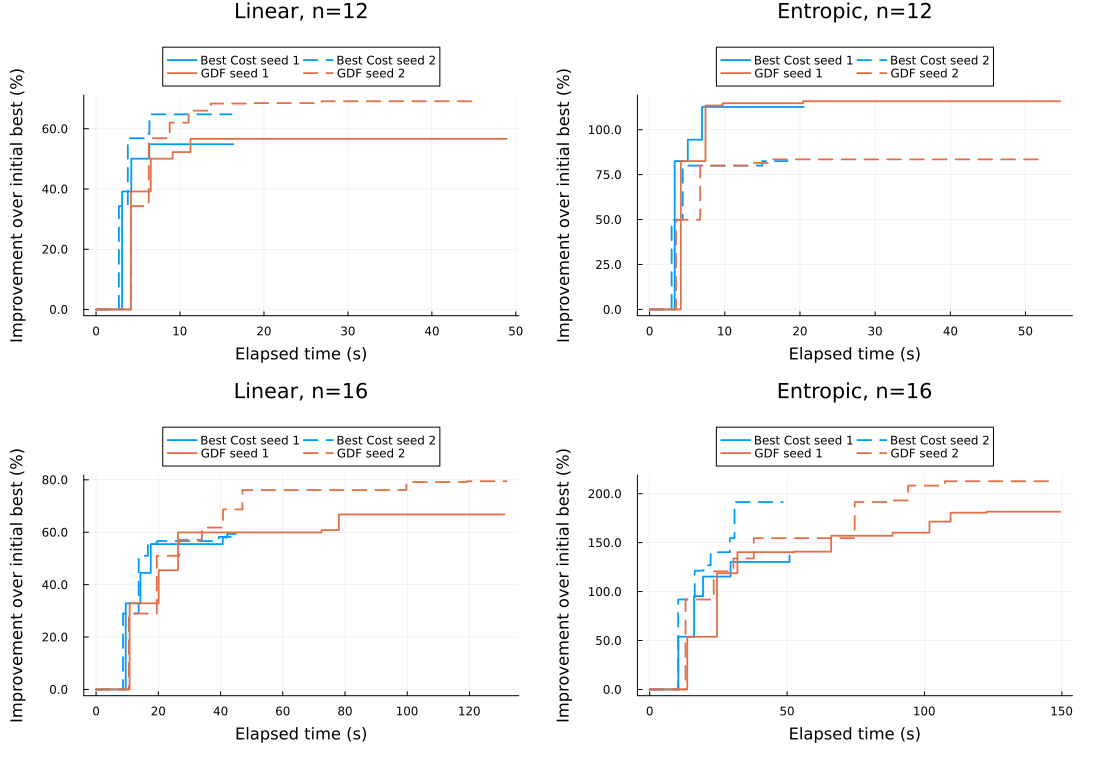

In [4]:
display(Image(filename=str(root / "examples/add_runtime_pilot/gain_by_time.png")))

## Individual paired checkpoints

In [5]:
display(HTML(html_table(paired, PAIR_COLUMNS)))

Iterations,n,Objective,Seed repeat,Best Cost (s),GDF (s),Time ratio,GDF improvement (%),Graph (s),Best calls,GDF calls
10,12,entropic,1,13.0,28.8,2.22,1.5,9.09,250797,268314
10,12,entropic,2,11.5,27.7,2.41,1.9,8.42,251738,268840
10,12,linear,1,9.90,26.9,2.72,1.2,8.30,250035,269107
10,12,linear,2,10.4,24.8,2.39,2.3,8.35,250071,269455
10,16,entropic,1,32.6,81.1,2.49,11.6,19.7,246751,261213
10,16,entropic,2,32.6,80.7,2.48,0.0,19.8,247105,262911
10,16,linear,1,30.2,72.4,2.39,3.4,17.6,244268,258498
10,16,linear,2,28.8,70.4,2.44,12.4,17.1,245240,258723
20,12,entropic,1,20.5,54.6,2.66,1.5,18.4,489135,522699
20,12,entropic,2,18.4,52.7,2.87,0.5,17.5,491632,523237


## Common observed elapsed time

For each completed pair, use the smaller final elapsed time. Read each incumbent at its last completed iteration at or before that time. Neither trajectory is extrapolated beyond its observed run. Improvements within an unfinished iteration are not logged, so this is a checkpoint-resolution diagnostic, not a newly executed fixed-time experiment.

In [6]:
common = common_time(arms)
display(HTML(html_table(common, COMMON_COLUMNS)))

n,Objective,Repeat,Common time (s),Best completed iterations,GDF completed iterations,Best cost,GDF cost,GDF improvement (%)
12,entropic,1,20.5,20,7,-1.83,-1.86,1.5
12,entropic,2,18.4,20,6,-1.85,-1.86,0.5
12,linear,1,16.3,20,5,-457.4,-462.7,1.2
12,linear,2,16.1,20,6,-450.8,-460.5,2.2
16,entropic,1,50.9,20,5,-1.75,-1.77,1.4
16,entropic,2,48.4,20,5,-2.03,-1.77,-12.6
16,linear,1,44.9,20,5,-576.0,-578.2,0.4
16,linear,2,44.3,20,5,-529.2,-564.3,6.6


## Twenty-iteration resources and phase timings

In [7]:
final = [r for r in cp if r['iteration'] == 20]
display(HTML(html_table(final, RESOURCE_COLUMNS)))

n,Objective,Repeat,Strategy,Time (s),CPU (% of one logical CPU),Sampled peak RSS (MiB),Sampled peak private bytes (MiB),Minimum available system RAM (MiB),Cumulative allocations (GiB),GC (s)
12,entropic,1,best_cost,20.5,93.8,1437.6,1700.4,1101.5,6.95,4.93
12,entropic,1,gdf,54.6,96.4,1484.4,1652.2,912.6,11.0,8.52
12,entropic,2,best_cost,18.4,96.6,1462.6,1646.7,1024.4,6.85,4.69
12,entropic,2,gdf,52.7,96.9,1332.6,1698.6,1026.3,11.0,7.95
16,entropic,1,best_cost,50.9,96.4,1791.1,2090.1,758.4,16.2,10.7
16,entropic,1,gdf,149.4,96.6,1827.1,2284.8,615.1,28.2,22.2
16,entropic,2,best_cost,48.4,98.6,1662.8,2012.9,893.5,16.5,10.5
16,entropic,2,gdf,146.6,96.9,1847.4,2379.5,636.7,28.3,21.3
12,linear,1,best_cost,16.3,91.3,1477.4,1653.5,1539.3,5.71,4.15
12,linear,1,gdf,48.9,91.9,1357.2,1687.2,1300.9,9.48,6.82


In [8]:
display(HTML(html_table(final, PHASE_COLUMNS)))

n,Objective,Repeat,Strategy,Build/norm (s),Train (s),Sample (s),Model pool (s),History/source (s),Selection (s),Graph within selection (s),Elite update (s)
12,entropic,1,best_cost,5.74,9.97,1.64,0.83,0.29,1.24,0.00,0.48
12,entropic,1,gdf,6.79,21.8,3.77,1.06,0.53,20.3,18.4,0.08
12,entropic,2,best_cost,5.05,9.74,1.53,0.30,0.46,1.01,0.00,0.10
12,entropic,2,gdf,5.83,21.8,3.38,0.60,0.42,20.4,17.5,0.08
16,entropic,1,best_cost,12.5,30.3,4.24,1.25,0.64,1.60,0.00,0.13
16,entropic,1,gdf,18.5,72.9,11.2,0.67,1.31,44.4,40.4,0.13
16,entropic,2,best_cost,10.3,30.2,4.39,0.49,0.56,2.10,0.00,0.13
16,entropic,2,gdf,19.1,73.0,9.40,0.53,1.12,42.4,40.0,0.80
12,linear,1,best_cost,3.97,9.23,1.44,0.98,0.28,0.19,0.00,0.04
12,linear,1,gdf,5.66,19.9,3.33,1.06,0.38,18.3,18.2,0.04


## Preliminary findings

- **Linear, n=12**: Best Cost 16.2 s, GDF 47.0 s (mean paired time ratio 2.90; range 2.80–2.99). Mean GDF final-cost improvement 1.9% (range 1.2–2.6%). Graph distance consumes 38.1% of GDF elapsed time. The mean paired objective-call ratio is 1.071.
- **Entropic, n=12**: Best Cost 19.4 s, GDF 53.6 s (mean paired time ratio 2.77; range 2.66–2.87). Mean GDF final-cost improvement 1.0% (range 0.5–1.5%). Graph distance consumes 33.5% of GDF elapsed time. The mean paired objective-call ratio is 1.066.
- **Linear, n=16**: Best Cost 44.6 s, GDF 131.6 s (mean paired time ratio 2.95; range 2.92–2.98). Mean GDF final-cost improvement 9.0% (range 4.7–13.4%). Graph distance consumes 27.9% of GDF elapsed time. The mean paired objective-call ratio is 1.058.
- **Entropic, n=16**: Best Cost 49.7 s, GDF 148.0 s (mean paired time ratio 2.98; range 2.94–3.03). Mean GDF final-cost improvement 13.1% (range 7.3–18.8%). Graph distance consumes 27.2% of GDF elapsed time. The mean paired objective-call ratio is 1.072.

At the common observed elapsed-time checkpoint, GDF wins in 7/8 pairs. Mean paired improvements by setting are: linear, n=12: 1.7%, entropic, n=12: 1.0%, linear, n=16: 3.5%, entropic, n=16: -5.6%. In particular, the second entropic n=16 run favors Best Cost at this time horizon, although GDF catches up and wins by iteration 20. This prevents a uniform claim of time-budget superiority.

A better result after the same iterations is distinct from a better result after the same elapsed time. The time-based curves allow comparison only where both trajectories are observed. Checkpoints report completed iterations: intra-iteration incumbent improvements are not timestamped, so time curves are conservative step functions. A plateau is evidence of stagnation within this run, not proof of an inescapable local minimum. The entropic objective here is a cheap synthetic function; the effect of an expensive external oracle is not directly measured. Objective-call counts and phase timings separate that question from graph-distance overhead. Although graph distance itself makes no objective calls, different sample uniqueness and subsequent training sets can change the total number of objective calls; an expensive oracle therefore does not automatically make total runtimes equal.

## Reproduction and raw outputs

Run `python scripts/run_ADD_runtime_local.py` on Windows to resume missing solver arms.
Run `python scripts/add_runtime_report.py`, then
`julia --project=. --threads=1 scripts/plot_ADD_runtime.jl`, then rerun the report builder.
The notebook's Python cells reload saved CSVs; they do not launch optimizers.
Each solver folder contains per-iteration costs/calls/phase times, a one-second process monitor,
configuration, initial-data hash, and the full final result in JLD2. Source coefficients are saved in that file.
The summary JLD2 also records cumulative allocations and GC time.
